# Лабораторная работа №1. Метод обратного распространения ошибки

**Студент:** Мальцев М.К.  
**Группа:** 3825М1ПР1

Цель работы - реализовать обучение двухслойной полносвязной сети с одним скрытым
слоем для распознавания цифр MNIST. Все градиенты вычисляются вручную средствами NumPy.

Архитектура: **784 → 300 → 10**, ReLU в скрытом слое, softmax на выходе,
кросс-энтропия и стохастический градиентный спуск по мини-батчам.

In [4]:
from pathlib import Path
import time

import kagglehub
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)

NumPy: 1.26.4


In [5]:
hidden_size = 300
learning_rate = 0.1
batch_size = 32
epochs = 20
num_classes = 10

## 1. Данные

[MNIST с Kaggle](https://www.kaggle.com/datasets/hojjatk/mnist-dataset): 60 000
тренировочных и 10 000 тестовых изображений размером 28×28.

Данные загружаются через `kagglehub`. При чтении пропускаются заголовки:
16 байт у изображений и 8 байт у меток.

In [6]:
path = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Path to dataset files:", path)
data_dir = Path(path)

train_images = np.fromfile(data_dir / "train-images.idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
train_labels = np.fromfile(data_dir / "train-labels.idx1-ubyte", dtype=np.uint8, offset=8)
test_images = np.fromfile(data_dir / "t10k-images.idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
test_labels = np.fromfile(data_dir / "t10k-labels.idx1-ubyte", dtype=np.uint8, offset=8)

100%|████████████████████████████████████████████████████████████| 22.0M/22.0M [00:03<00:00, 6.55MB/s]

Extracting files...


Path to dataset files: /Users/maltsev/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1


## 2. Предобработка

Разворачиваем изображение 28×28 в строку из 784 чисел и делим яркости на 255.
Получаются вещественные признаки в диапазоне [0, 1]. 

Используем `float32`, у MNIST есть стандартное разделение на тестовую и обучающую выборку, используем его. Тестовые примеры в обучение не входят.

Для меток используем два представления:

- `y_train`, `y_test`: целочисленные номера классов для оценки качества
- `Y_train`: one-hot строки для градиента, например:
  - цифре 2 соответствует`[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]`.
  - цифре 5 соответствует`[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`.

In [13]:
X_train = train_images.reshape(-1, 784).astype(np.float32) / 255.0
X_test = test_images.reshape(-1, 784).astype(np.float32) / 255.0
y_train = train_labels.astype(np.int64)
y_test = test_labels.astype(np.int64)
Y_train = np.eye(num_classes, dtype=np.float32)[y_train]

print("Тренировочная выборка:", X_train.shape, "; метки:", y_train.shape)
print("Тестовая выборка:", X_test.shape, "; метки:", y_test.shape)
print("Размерность изображения:", train_images[0].shape)
print("Размерность одной метки:", y_train[0].shape)
print("One-hot метки:", Y_train.shape)
print("Пример метки:", y_train[0], "→", Y_train[0])

Тренировочная выборка: (60000, 784) ; метки: (60000,)
Тестовая выборка: (10000, 784) ; метки: (10000,)
Размерность изображения: (28, 28)
Размерность одной метки: ()
One-hot метки: (60000, 10)
Пример метки: 5 → [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Примеры того, как выглядят цифры MNIST

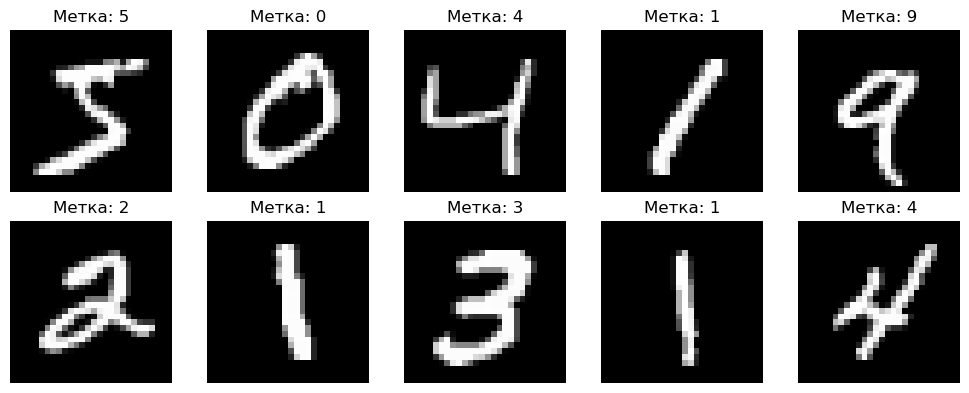

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for index, ax in enumerate(axes.flat):
    ax.imshow(X_train[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Метка: {y_train[index]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Нейронная сеть

Примеры расположены по строкам матрицы $X$.

$$Z_1=XW_1+b_1,\qquad H=\operatorname{ReLU}(Z_1),\qquad Z_2=HW_2+b_2.$$

$$P_{ij}=\frac{e^{Z_{2,ij}-m_i}}{\sum_k e^{Z_{2,ik}-m_i}},\qquad m_i=\max_j Z_{2,ij}.$$

Вычитание максимума сохраняет softmax и предотвращает переполнение экспоненты.
Случайные числа со средним 0 и стандартным отклонением 1 умножаем на
$\sqrt{2/784}$ для первого слоя и $\sqrt{1/300}$ для выходного.
Таким образом задаем дисперсии $2/784$ и $1/300$ и сохраняем нулевое математическое ожидание.
Масштаб ограничивает разброс начальных весов.

In [16]:
input_size = X_train.shape[1]

W1 = (np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)).astype(np.float32)
b1 = np.zeros(hidden_size, dtype=np.float32)
W2 = (np.random.randn(hidden_size, num_classes) * np.sqrt(1.0 / hidden_size)).astype(np.float32)
b2 = np.zeros(num_classes, dtype=np.float32)

## 4. Обучение

Кросс-энтропия для одного примера с правильным классом $y$:

$$\ell=-\log p_y=-z_y+\log\sum_j e^{z_j},\qquad
\frac{\partial\ell}{\partial z_j}=p_j-\mathbf{1}[j=y].$$

Для батча размера $B$ с one-hot метками $Y$:

$$L=-\frac{1}{B}\sum_i\sum_j Y_{ij}\log P_{ij},\qquad D_2=\frac{P-Y}{B}.$$

$$\nabla_{W_2}L=H^TD_2,\qquad \nabla_{b_2}L=\sum_i D_{2,i}.$$

$$D_1=(D_2W_2^T)\odot\mathbf{1}[Z_1>0],\qquad
\nabla_{W_1}L=X^TD_1,\qquad \nabla_{b_1}L=\sum_i D_{1,i}.$$

Шаг SGD: $\theta\leftarrow\theta-\eta\nabla_\theta L$.
Все градиенты вычисляются до обновления весов; деление на $B$ выполняется один раз.
Логарифмы вероятностей вычисляются как $\log P_{ij}=Z_{2,ij}-\log\sum_k e^{Z_{2,ik}}$
по сдвинутым логитам, без взятия логарифма округлённой в ноль вероятности.
Кросс-энтропия усредняется по примерам, обработанным в течение эпохи,
и сохраняется для графика. Ошибка классификации оценивается отдельно на всей
тренировочной выборке при итоговых весах эпохи.

In [17]:
train_errors = []
train_losses = []
training_start = time.perf_counter()

for epoch in range(1, epochs + 1):
    epoch_start = time.perf_counter()
    order = np.random.permutation(len(X_train))
    loss_sum = 0.0

    for start in range(0, len(X_train), batch_size):
        indices = order[start:start + batch_size]
        X_batch = X_train[indices]
        Y_batch = Y_train[indices]

        Z1 = X_batch @ W1 + b1
        H = np.maximum(0, Z1)
        Z2 = H @ W2 + b2
        Z2 = Z2 - Z2.max(axis=1, keepdims=True)
        exp_logits = np.exp(Z2)
        probabilities = exp_logits / exp_logits.sum(axis=1, keepdims=True)
        log_probabilities = Z2 - np.log(exp_logits.sum(axis=1, keepdims=True))
        loss = -np.mean(np.sum(Y_batch * log_probabilities, axis=1))
        loss_sum += loss * len(X_batch)

        dZ2 = (probabilities - Y_batch) / len(X_batch)
        dW2 = H.T @ dZ2
        db2 = dZ2.sum(axis=0)
        dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
        dW1 = X_batch.T @ dZ1
        db1 = dZ1.sum(axis=0)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    H_train = np.maximum(0, X_train @ W1 + b1)
    train_predictions = (H_train @ W2 + b2).argmax(axis=1)
    train_loss = loss_sum / len(X_train)
    train_losses.append(train_loss)
    train_error = np.mean(train_predictions != y_train)
    train_errors.append(train_error)
    epoch_time = time.perf_counter() - epoch_start

    print(f"Эпоха {epoch}: CE {train_loss:.4f}, ошибка {train_error:.2%}, время {epoch_time:.2f} с")

training_time = time.perf_counter() - training_start
print(f"Общее время: {training_time:.2f} с")

Эпоха 1: CE 0.2987, ошибка 4.44%, время 1.46 с
Эпоха 2: CE 0.1370, ошибка 2.86%, время 1.69 с
Эпоха 3: CE 0.0945, ошибка 2.13%, время 1.33 с
Эпоха 4: CE 0.0726, ошибка 1.57%, время 1.43 с
Эпоха 5: CE 0.0580, ошибка 1.30%, время 1.34 с
Эпоха 6: CE 0.0478, ошибка 1.00%, время 1.37 с
Эпоха 7: CE 0.0403, ошибка 0.80%, время 1.33 с
Эпоха 8: CE 0.0334, ошибка 0.78%, время 1.41 с
Эпоха 9: CE 0.0286, ошибка 0.50%, время 1.84 с
Эпоха 10: CE 0.0239, ошибка 0.45%, время 1.60 с
Эпоха 11: CE 0.0200, ошибка 0.28%, время 1.40 с
Эпоха 12: CE 0.0172, ошибка 0.21%, время 1.35 с
Эпоха 13: CE 0.0146, ошибка 0.13%, время 1.32 с
Эпоха 14: CE 0.0126, ошибка 0.11%, время 1.26 с
Эпоха 15: CE 0.0108, ошибка 0.08%, время 1.29 с
Эпоха 16: CE 0.0093, ошибка 0.05%, время 1.61 с
Эпоха 17: CE 0.0083, ошибка 0.07%, время 1.41 с
Эпоха 18: CE 0.0071, ошибка 0.02%, время 1.42 с
Эпоха 19: CE 0.0064, ошибка 0.02%, время 1.46 с
Эпоха 20: CE 0.0057, ошибка 0.01%, время 1.33 с
Общее время: 28.63 с


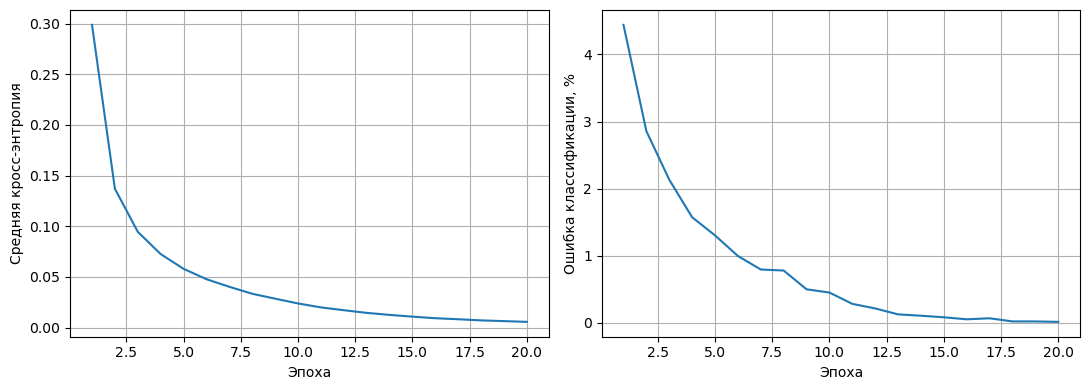

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(1, epochs + 1), train_losses)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Средняя кросс-энтропия")
axes[0].grid()

axes[1].plot(range(1, epochs + 1), np.array(train_errors) * 100)
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Ошибка классификации, %")
axes[1].grid()

plt.tight_layout()
plt.show()

## 5. Тестирование

Ошибка классификации - доля неправильных ответов, точность равна $1-\mathrm{ошибка}$.
Для выбора класса достаточно `argmax` логитов: softmax сохраняет их порядок.
Веса при оценке не изменяются.

In [19]:
H_test = np.maximum(0, X_test @ W1 + b1)
test_predictions = (H_test @ W2 + b2).argmax(axis=1)
test_error = np.mean(test_predictions != y_test)

print(f"Точность на тесте: {1 - test_error:.2%}")
print(f"Ошибка на тесте: {test_error:.2%}")

Точность на тесте: 98.21%
Ошибка на тесте: 1.79%


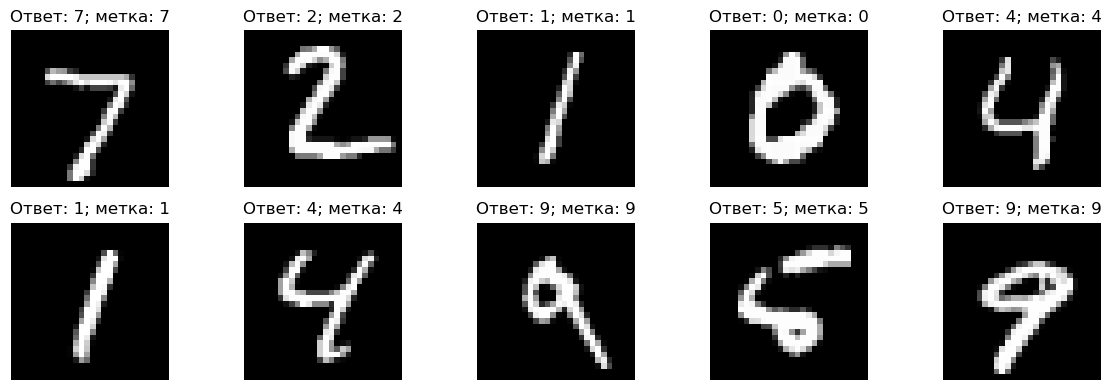

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(12, 4))

for index, ax in enumerate(axes.flat):
    ax.imshow(X_test[index].reshape(28, 28), cmap="gray")
    ax.set_title(f"Ответ: {test_predictions[index]}; метка: {y_test[index]}")
    ax.axis("off")

plt.tight_layout()
plt.show()